# ECON 422 · AR, MA, and DML for time series
November 2 practice. Three parts: (1) AR models and unit roots, (2) MA models: maximum-likelihood estimation and forecasting, (3) DML for time series with reverse cross-fitting, on U.S. inflation data from FRED, with a one-step reliability check. Run the cells in order.

In [ ]:
# Install the packages this notebook uses (only needed once per environment)
#%pip install -q numpy pandas matplotlib scipy scikit-learn statsmodels requests

SyntaxError: invalid syntax (3008831053.py, line 3)

In [1]:
# Copy and paste from Quizzes '[Week11] (Nov2) Exercise'.
# Packages: numpy/pandas for data, matplotlib for figures, scikit-learn for the ML learners
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Figure style and a small colour palette used throughout
plt.rcParams.update({'figure.figsize': (9, 3), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'ar': '#1f6fb2', 'ma': '#d9661f', 'grey': '#8c8c8c', 'green': '#9DB873', 'pink': '#E59AAB'}

## 1. AR models: how long does a shock last?
$y_t=\phi\,y_{t-1}+\varepsilon_t$. Feed the **same** 200 shocks into $\phi=0.5$, $\phi=0.95$ and $\phi=1$ (a unit root, i.e. a random walk). Which paths return to zero? What is left after differencing the random walk?

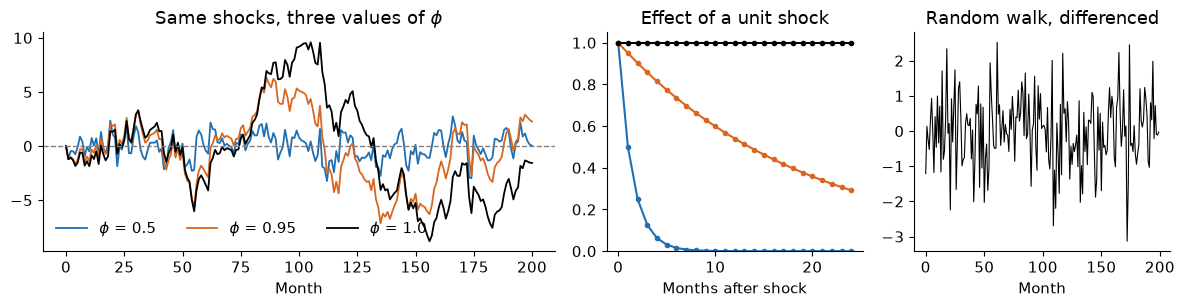

phi = 0.5 : lag-1 correlation of level = 0.51
phi = 0.95: lag-1 correlation of level = 0.95
phi = 1.0 : lag-1 correlation of level = 0.97
Differenced random walk equals the shocks: True


In [2]:
# ---- 1. Draw one set of shocks, reused for every value of phi ----
rng = np.random.default_rng(28)          # fixed seed so results are reproducible
n = 200; shocks = rng.normal(size=n)     # 200 standard-normal shocks

def ar_path(phi, e):
    '''Simulate y_t = phi * y_{t-1} + e_t, starting from y_0 = 0.'''
    y = np.zeros(len(e) + 1)
    for t in range(1, len(y)):
        y[t] = phi * y[t-1] + e[t-1]     # last month's value, scaled by phi, plus a new shock
    return y

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={'width_ratios': [2, 1, 1]})

# ---- 2. Left panel: the three simulated paths ----
for phi, c in [(.5, C['ar']), (.95, C['ma']), (1., 'black')]:
    ax[0].plot(ar_path(phi, shocks), color=c, lw=1.3, label=f'$\\phi$ = {phi}')
ax[0].axhline(0, color='grey', ls='--', lw=1); ax[0].set(title='Same shocks, three values of $\\phi$', xlabel='Month')
ax[0].legend(frameon=False, ncol=3)

# ---- 3. Middle panel: share of a one-unit shock left after h months = phi^h ----
h = np.arange(0, 25)
for phi, c in [(.5, C['ar']), (.95, C['ma']), (1., 'black')]:
    ax[1].plot(h, phi**h, 'o-', ms=3, color=c)
ax[1].set(title='Effect of a unit shock', xlabel='Months after shock', ylim=(0, 1.05))

# ---- 4. Right panel: first difference of the random walk (phi = 1) ----
rw = ar_path(1., shocks)
ax[2].plot(np.diff(rw), color='black', lw=.8); ax[2].set(title='Random walk, differenced', xlabel='Month')
plt.tight_layout(); plt.show()

# ---- 5. Numbers: how strongly each month is tied to the previous one ----
for phi in [.5, .95, 1.]:
    y = ar_path(phi, shocks)
    print(f'phi = {phi:<4}: lag-1 correlation of level = {np.corrcoef(y[:-1], y[1:])[0,1]:.2f}')
# Differencing a random walk should give back exactly the shocks we fed in
print('Differenced random walk equals the shocks:', np.allclose(np.diff(rw), shocks))

**Solution.** With $\phi=0.5$ a shock halves every month and the path hugs zero. With $\phi=0.95$ it fades slowly, so the path takes long swings but still comes back. With $\phi=1$ a shock **never** fades (middle panel: the black line stays at 1), so the path wanders off and its variance keeps growing: the series is not stationary, and averaging over time no longer estimates a fixed mean. Differencing the random walk, $\Delta y_t=\varepsilon_t$, recovers the shocks exactly, which is why unit-root series are differenced before modelling.

## 2. MA models: estimate by maximum likelihood, then forecast
Simulate 300 months of inflation from an MA(1), $y_t=\mu+\varepsilon_t+\theta\varepsilon_{t-1}$ with $\mu=0.30$, $\theta=0.5$, $\sigma=0.2$. Use the first 240 months to **estimate** $(\mu,\theta,\sigma)$ by maximum likelihood, then **forecast** the last 60 months and compare with what actually happened.

**The likelihood.** The shocks are not observed, but given candidate values they can be rebuilt one month at a time, starting from $\varepsilon_0=0$:
$$\varepsilon_t=y_t-\mu-\theta\,\varepsilon_{t-1}.$$
Each rebuilt shock is that month's one-step forecast error. With Gaussian shocks the (conditional) log-likelihood is
$$\log L(\mu,\theta,\sigma)=-\tfrac T2\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{t=1}^T\varepsilon_t^2 ,$$
so maximising it means choosing $(\mu,\theta)$ that make the rebuilt forecast errors as small as possible. We restrict $|\theta|<1$ (invertibility).

In [3]:
from scipy.optimize import minimize

# ---- 1. Simulate an MA(1): y_t = mu + e_t + theta * e_{t-1} ----
mu0, theta0, sigma0, N, T_train = .30, .5, .2, 300, 240   # true parameters, sample size, training length
rng = np.random.default_rng(27)
e = rng.normal(0, sigma0, N + 1)                 # N+1 shocks: one extra for e_{t-1} in the first month
y = mu0 + e[1:] + theta0 * e[:-1]                # today's shock + theta x yesterday's shock
y_train, y_test = y[:T_train], y[T_train:]      # first 240 months to estimate, last 60 to test

# ---- 2. Rebuild the (unobserved) shocks from the data, given candidate mu and theta ----
def rebuild_shocks(y, mu, theta, eps0=0.):
    '''eps_t = y_t - mu - theta * eps_{t-1}, starting from the guess eps_0 = 0.
    Each eps_t is that month's one-step forecast error.'''
    eps = np.empty(len(y)); prev = eps0
    for t, yt in enumerate(y):
        eps[t] = yt - mu - theta * prev; prev = eps[t]
    return eps

# ---- 3. Negative Gaussian log-likelihood (minimising it = maximising the likelihood) ----
def neg_loglik(params, y):
    mu, theta, log_sigma = params                # sigma enters as log(sigma) so it stays positive
    eps = rebuild_shocks(y, mu, theta); s2 = np.exp(2 * log_sigma)
    return .5 * len(y) * np.log(2 * np.pi * s2) + .5 * np.sum(eps**2) / s2

# ---- 4. Maximum likelihood: search over (mu, theta, log sigma), keeping |theta| < 1 ----
res = minimize(neg_loglik,
               x0=[y_train.mean(), 0., np.log(y_train.std())],      # starting values
               args=(y_train,), method='L-BFGS-B',
               bounds=[(None, None), (-.99, .99), (None, None)])    # invertibility: |theta| < 1
mu_hat, theta_hat, sigma_hat = res.x[0], res.x[1], np.exp(res.x[2])
print(pd.DataFrame({'true': [mu0, theta0, sigma0], 'MLE (by hand)': [mu_hat, theta_hat, sigma_hat]},
                   index=['mu', 'theta', 'sigma']).round(3).to_string())

# ---- 5. Cross-check with statsmodels (exact Gaussian MLE via the Kalman filter; also gives s.e.) ----
# Optional: skipped with a message if statsmodels is not installed (run the install cell at the top).
try:
    from statsmodels.tsa.arima.model import ARIMA
    sm_fit = ARIMA(y_train, order=(0, 0, 1), trend='c').fit()   # order=(p, d, q) = (0, 0, 1) is an MA(1)
    print('\nstatsmodels ARIMA(0,0,1):'); print(sm_fit.summary().tables[1])   # sigma2 = sigma^2
except ImportError:
    print('\n(statsmodels not installed: skipping the cross-check. Run the install cell at the top.)')

       true  MLE (by hand)
mu      0.3          0.301
theta   0.5          0.508
sigma   0.2          0.195

statsmodels ARIMA(0,0,1):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3012      0.019     15.887      0.000       0.264       0.338
ma.L1          0.5061      0.059      8.605      0.000       0.391       0.621
sigma2         0.0382      0.004      9.780      0.000       0.031       0.046


Average |rebuilt - true| shock: first 5 months 0.048, rest 0.002


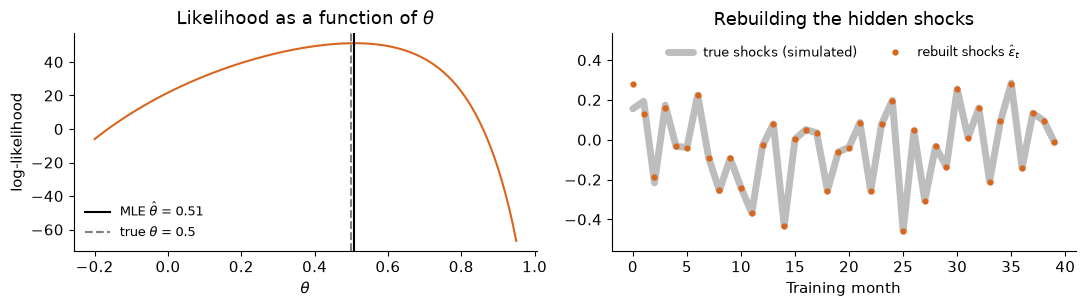

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))

# ---- Left: log-likelihood over a grid of theta values (mu and sigma held at their MLEs) ----
grid = np.linspace(-.2, .95, 116)
ll = [-neg_loglik([mu_hat, th, np.log(sigma_hat)], y_train) for th in grid]
ax[0].plot(grid, ll, color=C['ma'])
ax[0].axvline(theta_hat, color='black', lw=1.5, label=f'MLE $\\hat\\theta$ = {theta_hat:.2f}')
ax[0].axvline(theta0, color='grey', ls='--', label=f'true $\\theta$ = {theta0}')
ax[0].set(xlabel='$\\theta$', ylabel='log-likelihood', title='Likelihood as a function of $\\theta$')
ax[0].legend(frameon=False, fontsize=9)

# ---- Right: shocks rebuilt from the data vs. the true simulated shocks ----
eps_hat = rebuild_shocks(y_train, mu_hat, theta_hat)   # uses only the observed y and the estimates
true_eps = e[1:T_train + 1]                            # the shocks drawn in the simulation (never observed in real data)
m = np.arange(40)                                      # first 40 training months
ax[1].plot(m, true_eps[m], color='#bdbdbd', lw=5, solid_capstyle='round', label='true shocks (simulated)')
ax[1].plot(m, eps_hat[m], 'o', color=C['ma'], ms=3.5, label='rebuilt shocks $\\hat\\varepsilon_t$')
ax[1].set(xlabel='Training month', title='Rebuilding the hidden shocks')
ax[1].legend(frameon=False, fontsize=9, ncol=2, loc='upper center', bbox_to_anchor=(.5, 1.0))
ax[1].set_ylim(true_eps[m].min() - .1, true_eps[m].max() + .25)

# The gap is larger at first (because of the guess eps_0 = 0) and then vanishes
print(f'Average |rebuilt - true| shock: first 5 months {np.abs(eps_hat[:5]-true_eps[:5]).mean():.3f}, '
      f'rest {np.abs(eps_hat[5:]-true_eps[5:]).mean():.3f}')
plt.tight_layout(); plt.show()

**Reading the figures.** *Left:* the log-likelihood for each candidate $\theta$ (holding $\hat\mu,\hat\sigma$ fixed); its peak is the MLE, close to the true value. *Right:* the grey band is the **true shocks**, the $\varepsilon_t$ the simulation drew to generate the data. In real data we never see them; we know them here only because we simulated the series. The orange dots are the shocks **rebuilt** from the observed $y_t$ alone, using $\hat\mu,\hat\theta$ and the recursion above. The dots sit on the band: the hidden shocks can be recovered from the data. Any small gap in the first few months comes from the starting guess $\varepsilon_0=0$, and it dies out quickly because $|\hat\theta|<1$ (invertibility).

One-step RMSE, MA(1) forecast       : 0.232
One-step RMSE, training-mean forecast: 0.279
Best possible (shock s.d.)          : 0.200


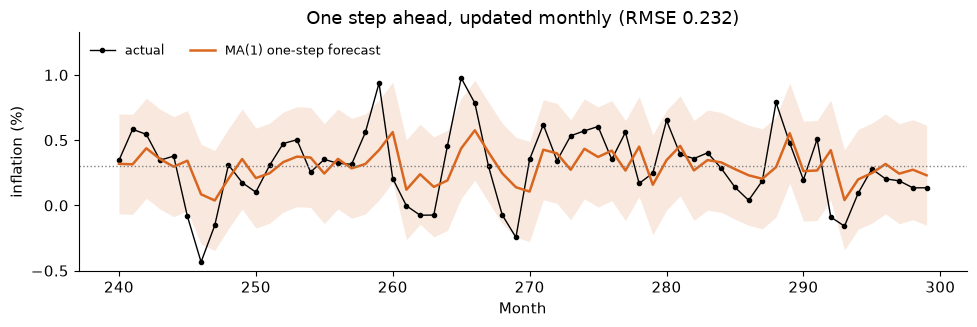

In [5]:
# ---- 1. One-step-ahead forecasts over the 60 test months ----
# Start from the last shock of the training sample, then move forward one month at a time.
eps_prev = rebuild_shocks(y_train, mu_hat, theta_hat)[-1]
one_step = []
for actual in y_test:
    f = mu_hat + theta_hat * eps_prev           # forecast for this month, made at the end of last month
    one_step.append(f)
    eps_prev = actual - f                       # once the month is observed, its forecast error is the new shock
one_step = np.array(one_step)

# ---- 2. Forecast accuracy: root mean squared error (RMSE) against the actual values ----
rmse = lambda f: np.sqrt(np.mean((y_test - f)**2))
print(f'One-step RMSE, MA(1) forecast       : {rmse(one_step):.3f}')
print(f'One-step RMSE, training-mean forecast: {rmse(np.full(len(y_test), y_train.mean())):.3f}')   # benchmark
print(f'Best possible (shock s.d.)          : {sigma0:.3f}')   # the new shock is unpredictable

# ---- 3. Plot forecasts, a 95% band (forecast +/- 1.96 sigma) and the actual values ----
fig, ax = plt.subplots(figsize=(10, 3.4)); ax = [ax]
tt = np.arange(T_train, N)
ax[0].plot(tt, y_test, 'o-', color='black', ms=3, lw=1, label='actual')
ax[0].plot(tt, one_step, color=C['ma'], lw=1.8, label='MA(1) one-step forecast')
ax[0].fill_between(tt, one_step - 1.96 * sigma_hat, one_step + 1.96 * sigma_hat, color=C['ma'], alpha=.15, lw=0)
ax[0].axhline(mu_hat, color='grey', ls=':', lw=1)      # estimated mean
ax[0].set(xlabel='Month', ylabel='inflation (%)', title=f'One step ahead, updated monthly (RMSE {rmse(one_step):.3f})')
ax[0].set_ylim(top=y_test.max() + .35)
ax[0].legend(frameon=False, ncol=2, fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

**Questions.** (a) How close are $\hat\mu,\hat\theta,\hat\sigma$ to the truth, and does the hand-coded MLE agree with statsmodels? (b) Why does the one-step forecast beat the constant mean, but only modestly?

**Solution.** (a) With 240 months the estimates are close to $(0.30,\,0.5,\,0.2)$, and the two MLEs agree up to the treatment of the first observation (conditional vs. exact likelihood). (b) Each month, the MA(1) forecast uses last month's surprise, which explains part of this month's value; the rest is a brand-new shock nobody can predict, so the best achievable RMSE is $\sigma=0.2$. The mean-only forecast ignores last month's surprise, so its error is the whole MA term, with s.d. near $\sqrt{1+\theta^2}\,\sigma\approx0.22$.

## 3. DML for time series: inflation persistence
Model component $+$ ML. How much of last month's inflation carries into this month, once older inflation, labour-market news and interest-rate news are accounted for?
$$\pi_t=\phi_1\,\pi_{t-1}+g(X_t)+\varepsilon_t,\qquad D_t=\pi_{t-1},\qquad X_t=\big(\pi_{t-2},\dots,\pi_{t-L},\ \Delta u_{t-1},\Delta u_{t-2},\ \Delta i_{t-1},\Delta i_{t-2},\ \text{month dummies}\big).$$
$\phi_1$ enters linearly (the AR component); the nuisance function $g$ is learned by ML.

**Why time series need special cross-fitting.** DML fits the nuisance functions on one part of the sample and uses them to compute residuals in another part. With random folds, a training month can sit right next to a test month and share its shocks. **Reverse cross-fitting (RCF-DML)** splits the sample into $K$ consecutive blocks. To compute residuals for block $k$ (the held-out block), it trains on
- the **earlier** blocks, played forward as usual, and
- the **later** blocks, **played backwards**, so that "next month" plays the role of "last month".

Every block takes a turn as the held-out block, and every month is used for training. The price is three conditions on the whole design $(y_t, D_t, X_t)$:

| Condition | What it requires | Why RCF-DML needs it |
|---|---|---|
| 1. Stationarity | constant mean, variance and autocovariances | a nuisance function learned in one period must apply in another |
| 2. Time reversibility | the data look the same played backwards | the later blocks are used backwards, so the backward process must match the forward one |
| 3. Conditional stability | given the controls, the error and the regressor's residual carry no memory | otherwise shocks leak across block borders, and (with lags of $\pi$ in the design) the error is correlated with $\pi_{t-1}$ |

| Variable | FRED series | Transformation |
|---|---|---|
| Inflation $\pi_t$ | `CPIULFSL` (CPI, all items less food) | $100\,\Delta\log$ |
| Unemployment change $\Delta u_t$ | `UNRATE` | first difference |
| 10-year yield change $\Delta i_t$ | `GS10` | first difference |
| Term spread (robustness) | `GS10` − `TB3MS` | level |

**API key.** Get a free key at <https://fred.stlouisfed.org/docs/api/api_key.html>, then run the next cell and paste it when asked (or set the environment variable `FRED_API_KEY`).

In [6]:
import io, time, requests
from getpass import getpass

# FRED series used below (see the table above)
SERIES = ['CPIULFSL', 'UNRATE', 'GS10', 'TB3MS']

def fred_api(series_id, key, start):
    '''Download one series through the FRED API (needs a key). Raises a readable error on failure.'''
    url = 'https://api.stlouisfed.org/fred/series/observations'
    params = dict(series_id=series_id, api_key=key, file_type='json', observation_start=start)
    for attempt in range(3):                                   # retry: FRED occasionally hiccups
        r = requests.get(url, params=params, timeout=30)
        try:
            js = r.json()
        except ValueError:                                     # not JSON (e.g. an HTML error page)
            js = None
        if r.ok and js and 'observations' in js:
            return pd.Series({pd.Timestamp(o['date']): np.nan if o['value'] == '.' else float(o['value'])
                              for o in js['observations']}, name=series_id)
        if js and 'error_message' in js:                       # FRED explains the problem (e.g. bad key)
            raise RuntimeError(f"FRED API error for {series_id}: {js['error_message']}")
        time.sleep(1 + attempt)
    raise RuntimeError(f'FRED API returned HTTP {r.status_code} for {series_id}: {r.text[:200]!r}')

def fred_csv(series_id, start):
    '''Same FRED data via the public CSV download (no key needed). Used if the API call fails.'''
    r = requests.get('https://fred.stlouisfed.org/graph/fredgraph.csv', params={'id': series_id}, timeout=30)
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.text), na_values='.')
    s = pd.Series(df.iloc[:, 1].values, index=pd.to_datetime(df.iloc[:, 0]), name=series_id).astype(float)
    return s[s.index >= start]

def fred(series_id, key, start='1980-01-01'):
    '''Try the API first; if it fails, fall back to the CSV download and say so.'''
    try:
        return fred_api(series_id, key, start)
    except Exception as err:
        print(f'  {series_id}: API failed ({err}); using the public CSV download instead.')
        return fred_csv(series_id, start)

# ---- Read the API key (typed input is hidden). Strip spaces/quotes that sneak in when pasting. ----
key = (os.environ.get('FRED_API_KEY', '') or getpass('FRED API key: ')).strip().strip('"').strip("'")
if len(key) != 32:
    print(f'Warning: FRED keys are 32 characters; yours has {len(key)}. Check for a copy-paste error.')
raw = pd.concat([fred(s, key) for s in SERIES], axis=1).resample('MS').mean()   # common monthly calendar

# ---- Transform to the variables in the model (monthly) ----
data = pd.DataFrame({
    'pi':    100 * np.log(raw['CPIULFSL']).diff(),   # inflation: monthly % change in CPI less food
    'du':    raw['UNRATE'].diff(),                   # change in the unemployment rate (pp)
    'di':    raw['GS10'].diff(),                     # change in the 10-year Treasury yield (pp)
    'term':  raw['GS10'] - raw['TB3MS'],             # term spread (pp), used in the robustness check
}).dropna()
data = data.loc['1985':'2019']                       # baseline sample: after the Volcker disinflation, before COVID
print(f'FRED data: {data.index[0]:%Y-%m} to {data.index[-1]:%Y-%m},  {len(data)} months')

FRED data: 1985-01 to 2019-12,  420 months


**The estimator.** `rcf_dml` builds the design twice: once forward (controls are *lags*), once from the time-reversed data (the same columns become *leads*). For each of the $K=5$ blocks it trains two learners, one for $E[\pi_t\mid X_t]$ and one for $E[\pi_{t-1}\mid X_t]$, on the forward rows of the earlier blocks plus the reversed rows of the later blocks. It then computes the residuals $R_t=\pi_t-\hat\ell(X_t)$ and $V_t=\pi_{t-1}-\hat m(X_t)$ in the held-out block, regresses $R$ on $V$, and reports a HAC (Newey–West) standard error.

**The learner.** Inflation dynamics are close to linear, and a random forest alone approximates a linear function by steps, which leaves memory in the residuals. So the learner first fits a **linear regression** on the controls, then a **random forest** on what is left over (the nonlinear part).

In [7]:
from sklearn.base import BaseEstimator, RegressorMixin

class LinearPlusForest(BaseEstimator, RegressorMixin):
    '''Nuisance learner: linear regression first, then a random forest on its leftovers.'''
    def fit(self, X, y):
        self.lin = LinearRegression().fit(X, y)
        self.rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=.5,
                                        random_state=0, n_jobs=-1).fit(X, y - self.lin.predict(X))
        return self
    def predict(self, X):
        return self.lin.predict(X) + self.rf.predict(X)

def make_design(df, L=12, controls=('du', 'di')):
    '''Columns y, D and controls X for  pi_t = phi_1 pi_{t-1} + g(X_t) + e_t.
    Applied to time-reversed data, every "lag" below becomes a "lead".'''
    d = {'y': df['pi'], 'D': df['pi'].shift(1)}
    for l in range(2, L + 1): d[f'pi_l{l}'] = df['pi'].shift(l)          # older inflation -> controls
    for c in controls:
        for l in (1, 2): d[f'{c}_l{l}'] = df[c].shift(l)                  # two lags of each control
    out = pd.DataFrame(d)
    for m in range(2, 13): out[f'month{m}'] = (out.index.month == m).astype(float)   # calendar-month dummies
    return out

def rcf_dml(df, L=12, controls=('du', 'di'), K=5, learner=LinearPlusForest):
    '''Reverse cross-fitting DML. Returns the estimate, HAC s.e., residuals R and V, and the error.'''
    fwd = make_design(df, L, controls)                                  # forward: controls are lags
    rev = make_design(df.iloc[::-1], L, controls).iloc[::-1]           # reversed: the same columns are leads
    idx = fwd.dropna().index
    Xcols = [c for c in fwd.columns if c not in ('y', 'D')]
    blocks = np.array_split(np.arange(len(idx)), K)                    # K consecutive blocks of months
    R, V = pd.Series(np.nan, index=idx), pd.Series(np.nan, index=idx)

    for k, b in enumerate(blocks):
        test = idx[b]
        earlier = [idx[j] for j in blocks[:k]]                          # earlier blocks: used forward
        later = [idx[j] for j in blocks[k + 1:]]                        # later blocks: used backwards
        train = pd.concat([fwd.loc[np.concatenate(earlier)] if earlier else fwd.iloc[:0],
                           rev.loc[np.concatenate(later)] if later else rev.iloc[:0]]).dropna()
        ell = learner().fit(train[Xcols].values, train['y'].values)    # E[pi_t | X_t]
        m = learner().fit(train[Xcols].values, train['D'].values)      # E[pi_{t-1} | X_t]
        R[test] = fwd.loc[test, 'y'] - ell.predict(fwd.loc[test, Xcols].values)
        V[test] = fwd.loc[test, 'D'] - m.predict(fwd.loc[test, Xcols].values)

    # Residual-on-residual regression and HAC (Newey-West) standard error
    phi = (V @ R) / (V @ V)
    err = R - phi * V                                                   # final DML error
    psi = (V * err).values; T = len(psi); Lh = int(4 * (T / 100) ** (2 / 9))
    om = psi @ psi / T + 2 * sum((1 - l / (Lh + 1)) * (psi[l:] @ psi[:-l]) / T for l in range(1, Lh + 1))
    se = np.sqrt(om / T) / np.mean(V.values ** 2)
    return dict(phi=phi, se=se, R=R, V=V, err=err, blocks=[idx[b] for b in blocks])

def report(fit, name='phi_1'):
    '''One-line table: estimate, HAC standard error and 95% confidence interval.'''
    b, s = fit['phi'], fit['se']
    return pd.DataFrame({'estimate': [round(b, 3)], 'HAC s.e.': [round(s, 3)],
                         '95% CI': [f'[{b - 1.96 * s:.3f}, {b + 1.96 * s:.3f}]']}, index=[name])

### The reliability check
Run this cell once. `rcf_verdict(...)` runs the three checks and prints **RELIABLE** or **NOT RELIABLE**, with a suggested fix if needed.
- *Before estimation* (data only): **(1)** every variable is stationary (ADF test); **(2)** no sign of an arrow of time, in each series and in each pair of series (Ramsey–Rothman test, $|t|<1.96$ at lags 1–3).
- *After estimation* (needs the residuals): **(3)** neither the error $\hat\varepsilon_t$ nor the regressor's residual $V_t$ has memory (Ljung–Box test, lag 12, $p>0.05$).

You do not need to follow the code; the comments say what each part does.

In [8]:
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

def _hac_t(z):
    '''t-statistic for mean(z) = 0 with a Newey-West standard error.'''
    z = np.asarray(z, float); m = z.mean(); z = z - m; T = len(z); L = int(4 * (T / 100) ** (2 / 9))
    v = z @ z / T + 2 * sum((1 - l / (L + 1)) * (z[l:] @ z[:-l]) / T for l in range(1, L + 1))
    return m / np.sqrt(v / T)

def _std(x):
    x = np.asarray(x, float); return (x - x.mean()) / x.std()

def _rev_one(x):
    '''Largest |t| for E[(x_t - x_{t-k})^3] = 0, k = 1..3: asymmetric rises and falls in one series.'''
    x = _std(x); return max(abs(_hac_t((x[k:] - x[:-k]) ** 3)) for k in (1, 2, 3))

def _rev_pair(x, w):
    '''Largest |t| for E[x_t^2 w_{t-k} - x_{t-k} w_t^2] = 0, k = 1..3: does x lead w differently than w leads x?'''
    x, w = _std(x), _std(w)
    return max(abs(_hac_t(x[k:] ** 2 * w[:-k] - x[:-k] * w[k:] ** 2)) for k in (1, 2, 3))

def rcf_verdict(name, variables, fit):
    '''variables: DataFrame of the series in the design (outcome and controls); fit: output of rcf_dml.'''
    rows, fixes = [], []
    v = variables.dropna()

    # (1) Stationarity: ADF rejects a unit root for every variable
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        bad = [c for c in v if adfuller(v[c].values, autolag='AIC')[1] >= .05]
    rows.append(('1. Stationarity (ADF, every variable)', 'pass' if not bad else 'FAIL: ' + ', '.join(bad)))
    if bad: fixes.append('difference the non-stationary variable(s) or shorten the sample')

    # (2) Time reversibility: each series and each pair of series
    t1 = {c: _rev_one(v[c].values) for c in v}
    t2 = {(a, b): _rev_pair(v[a].values, v[b].values) for a in v for b in v if a != b}
    worst1, worst2 = max(t1, key=t1.get), max(t2, key=t2.get)
    rows.append(('2a. Reversibility, each series', f'pass (largest |t| = {t1[worst1]:.2f})' if t1[worst1] < 1.96
                 else f'FAIL: {worst1} (|t| = {t1[worst1]:.2f})'))
    rows.append(('2b. Reversibility, each pair', f'pass (largest |t| = {t2[worst2]:.2f})' if t2[worst2] < 1.96
                 else f'FAIL: {worst2} (|t| = {t2[worst2]:.2f})'))
    if max(t1.values()) >= 1.96 or max(t2.values()) >= 1.96:
        fixes.append('drop or replace the irreversible variable (e.g. spiky series such as oil prices)')

    # (3) Conditional stability: no memory in the error or in the regressor's residual
    p_e = acorr_ljungbox(fit['err'].values, lags=[12], return_df=True)['lb_pvalue'].iloc[0]
    p_v = acorr_ljungbox(fit['V'].values, lags=[12], return_df=True)['lb_pvalue'].iloc[0]
    rows.append(('3a. Error has no memory (Ljung-Box)', f'pass (p = {p_e:.2f})' if p_e > .05 else f'FAIL (p = {p_e:.2f})'))
    rows.append(('3b. Regressor residual has no memory', f'pass (p = {p_v:.2f})' if p_v > .05 else f'FAIL (p = {p_v:.2f})'))
    if min(p_e, p_v) <= .05:
        fixes.append('add older lags (raise L), keep the month dummies, or use a learner that handles linear dynamics')

    verdict = 'NOT RELIABLE' if fixes else 'RELIABLE'
    print(f'\n=== Reliability check: {name} ===')
    for cond, res in rows: print(f'  {cond:<40} {res}')
    print(f'\n  VERDICT: {verdict}')
    for f in fixes: print('  - fix:', f)
    return verdict

### Exercise · Estimate $\phi_1$ and check the verdict
Baseline: $L=12$ (a year of older inflation in the controls), controls $\Delta u$ and $\Delta i$, $K=5$ blocks.

       estimate  HAC s.e.          95% CI
phi_1     0.528     0.093  [0.346, 0.709]

=== Reliability check: inflation persistence, L = 12 ===
  1. Stationarity (ADF, every variable)    pass
  2a. Reversibility, each series           pass (largest |t| = 1.62)
  2b. Reversibility, each pair             pass (largest |t| = 1.76)
  3a. Error has no memory (Ljung-Box)      pass (p = 0.98)
  3b. Regressor residual has no memory     pass (p = 0.69)

  VERDICT: RELIABLE

Naive AR(1) slope (OLS, no controls): 0.425


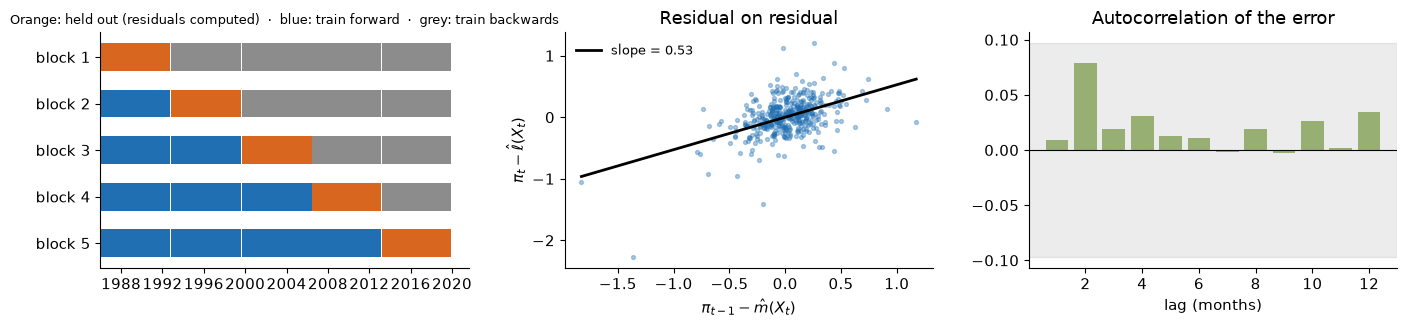

In [9]:
fit = rcf_dml(data, L=12, controls=('du', 'di'))
print(report(fit).to_string())
rcf_verdict('inflation persistence, L = 12', data[['pi', 'du', 'di']], fit)

# For comparison: plain OLS of pi_t on pi_{t-1} (no controls)
d0 = pd.concat([data['pi'], data['pi'].shift(1)], axis=1).dropna().values
print(f'\nNaive AR(1) slope (OLS, no controls): {np.polyfit(d0[:, 1], d0[:, 0], 1)[0]:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))

# Left: which blocks train the learners for each held-out block (earlier blocks forward, later blocks backwards)
for k, blk in enumerate(fit['blocks']):
    for j, other in enumerate(fit['blocks']):
        col = C['ma'] if j == k else (C['ar'] if j < k else C['grey'])
        ax[0].barh(k, other[-1] - other[0], left=other[0], color=col, height=.6)
ax[0].set_yticks(range(5)); ax[0].set_yticklabels([f'block {k+1}' for k in range(5)]); ax[0].invert_yaxis()
ax[0].set_title('Orange: held out (residuals computed)  ·  blue: train forward  ·  grey: train backwards', fontsize=9)

# Middle: residual on residual; the slope is phi_1
V, R, b = fit['V'], fit['R'], fit['phi']
ax[1].scatter(V, R, s=8, alpha=.35, color=C['ar'])
g = np.linspace(V.min(), V.max(), 2); ax[1].plot(g, b * g, color='black', lw=2, label=f'slope = {b:.2f}')
ax[1].set(xlabel='$\\pi_{t-1}-\\hat m(X_t)$', ylabel='$\\pi_t-\\hat\\ell(X_t)$', title='Residual on residual')
ax[1].legend(frameon=False, fontsize=9)

# Right: autocorrelation of the error (condition 3)
z = fit['err'].values - fit['err'].mean(); acf = [z[k:] @ z[:-k] / (z @ z) for k in range(1, 13)]
band = 1.96 / np.sqrt(len(z))
ax[2].bar(range(1, 13), acf, color=C['green']); ax[2].axhspan(-band, band, color='gray', alpha=.15)
ax[2].axhline(0, color='black', lw=.8); ax[2].set(xlabel='lag (months)', title='Autocorrelation of the error')
plt.tight_layout(); plt.show()

**Reading the results.**
- *Estimate.* $\hat\phi_1$ is the share of last month's inflation that carries into this month, holding older inflation, unemployment news and interest-rate news fixed. Compare it with the naive AR(1) slope: the two differ because the naive slope mixes the direct carry-over with everything that older inflation and the controls explain.
- *Left figure.* Each row is one round of cross-fitting. The orange block is **held out**: the learners are trained on the blue blocks (earlier months, forward) and the grey blocks (later months, played backwards), then used to compute the residuals $R_t$ and $V_t$ for the orange months. Each kind of training rests on a different condition:
  - *Blue (forward)* needs only **stationarity**: the learner predicts $\pi_t$ from past values, exactly as in the held-out block, and stationarity makes that relationship the same in both periods.
  - *Grey (backwards)* also needs **time reversibility**: here the learner predicts $\pi_t$ from *future* values, and we then apply it to the held-out block's *past* values. That is valid only if the data look the same played backwards. Oil prices, which spike up and drift down, would fail: reversed, they drift up and crash, and the learner would learn the wrong dynamics.
  - *Block borders* need **condition 3** (no memory in the residuals): training blocks sit right next to the held-out block, and this is what keeps shocks from leaking across the border.

  The held-out block itself is never reversed; its residuals always come from its own lags. Unlike forward-only splitting, every block takes a turn as the held-out block, including the first.
- *Middle figure.* The slope of the cloud is $\hat\phi_1$.
- *Right figure and verdict.* Bars inside the grey band mean the error behaves like a fresh shock. With lags of inflation in the design, this is decisive: an error with memory would be correlated with $\pi_{t-1}$, and $\hat\phi_1$ would be biased.
- *What the conditions do not prove.* "Not rejected" means no evidence against the condition, not proof that it holds. The reversibility test in particular has limited power, so the design should also make economic sense: all variables enter as changes or rates, not as trending levels, and none is a spiky series with sudden jumps and slow declines.

### Robustness · Does the answer depend on our choices?
Re-estimate with more older lags ($L=18, 24$) and with the term spread in place of the yield change. A reliable result should keep a **RELIABLE** verdict and a similar $\hat\phi_1$.


=== Reliability check: L = 12, controls = ('du', 'di') ===
  1. Stationarity (ADF, every variable)    pass
  2a. Reversibility, each series           pass (largest |t| = 1.62)
  2b. Reversibility, each pair             pass (largest |t| = 1.76)
  3a. Error has no memory (Ljung-Box)      pass (p = 0.98)
  3b. Regressor residual has no memory     pass (p = 0.69)

  VERDICT: RELIABLE

=== Reliability check: L = 18, controls = ('du', 'di') ===
  1. Stationarity (ADF, every variable)    pass
  2a. Reversibility, each series           pass (largest |t| = 1.62)
  2b. Reversibility, each pair             pass (largest |t| = 1.76)
  3a. Error has no memory (Ljung-Box)      pass (p = 1.00)
  3b. Regressor residual has no memory     pass (p = 0.78)

  VERDICT: RELIABLE

=== Reliability check: L = 24, controls = ('du', 'di') ===
  1. Stationarity (ADF, every variable)    pass
  2a. Reversibility, each series           pass (largest |t| = 1.62)
  2b. Reversibility, each pair             pass (larg

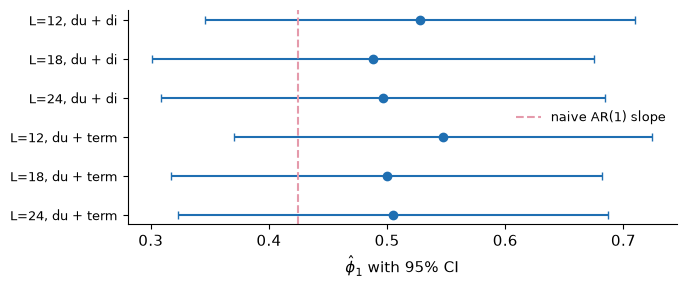

In [10]:
specs = [(12, ('du', 'di')), (18, ('du', 'di')), (24, ('du', 'di')),
         (12, ('du', 'term')), (18, ('du', 'term')), (24, ('du', 'term'))]
rows = []
for L, ctrl in specs:
    f = rcf_dml(data, L=L, controls=ctrl)
    v = rcf_verdict(f'L = {L}, controls = {ctrl}', data[['pi', *ctrl]], f)
    rows.append((L, ' + '.join(ctrl), f['phi'], f['se'], v))
rob = pd.DataFrame(rows, columns=['L', 'controls', 'phi_1', 'HAC s.e.', 'verdict'])
print('\n', rob.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
lab = [f'L={r.L}, {r.controls}' for r in rob.itertuples()]
ax.errorbar(rob['phi_1'], range(len(rob)), xerr=1.96 * rob['HAC s.e.'], fmt='o', color=C['ar'], capsize=3)
ax.axvline(np.polyfit(d0[:, 1], d0[:, 0], 1)[0], color=C['pink'], ls='--', label='naive AR(1) slope')
ax.set_yticks(range(len(rob))); ax.set_yticklabels(lab, fontsize=9); ax.invert_yaxis()
ax.set_xlabel('$\\hat\\phi_1$ with 95% CI'); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()